In [1]:
# This method is used when the distribution is skewed meaning not normal
# IQR lai proximity rule

In [2]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('placement.csv')

In [4]:
df.head(3)

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1


In [5]:
df['placement_exam_marks'].skew()

0.8356419499466834

In [6]:
df['placement_exam_marks'].describe()

count    1000.000000
mean       32.225000
std        19.130822
min         0.000000
25%        17.000000
50%        28.000000
75%        44.000000
max       100.000000
Name: placement_exam_marks, dtype: float64

<Axes: xlabel='placement_exam_marks'>

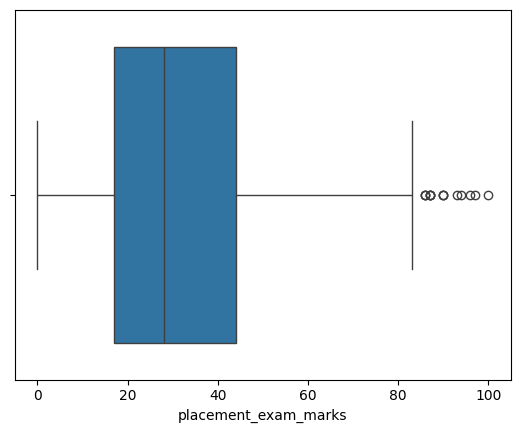

In [8]:
sns.boxplot(df['placement_exam_marks'], orient='h')

In [9]:
Q1=df['placement_exam_marks'].quantile(0.25)
Q3=df['placement_exam_marks'].quantile(0.75)

In [10]:
IQR = Q3-Q1

In [11]:
IQR

27.0

In [12]:
upper_limit = Q3+IQR*1.5
lower_limit = Q1-IQR*1.5

In [13]:
upper_limit

84.5

In [14]:
lower_limit

-23.5

In [15]:
df[df['placement_exam_marks']>upper_limit]

,cgpa,placement_exam_marks,placed
9,7.75,94.0,1
40,6.60,86.0,1
61,7.51,86.0,0
134,6.33,93.0,0
162,7.80,90.0,0
283,7.09,87.0,0
290,8.38,87.0,0
311,6.97,87.0,1
324,6.64,90.0,0
630,6.56,96.0,1


In [16]:
df[df['placement_exam_marks']<lower_limit]

,cgpa,placement_exam_marks,placed


In [28]:
new_df = df[(df['placement_exam_marks']<upper_limit) & (df['placement_exam_marks']>lower_limit)]

In [29]:
new_df.sample(4)

,cgpa,placement_exam_marks,placed
458,7.13,47.0,0
978,6.78,12.0,0
593,6.55,62.0,0
640,6.36,61.0,1


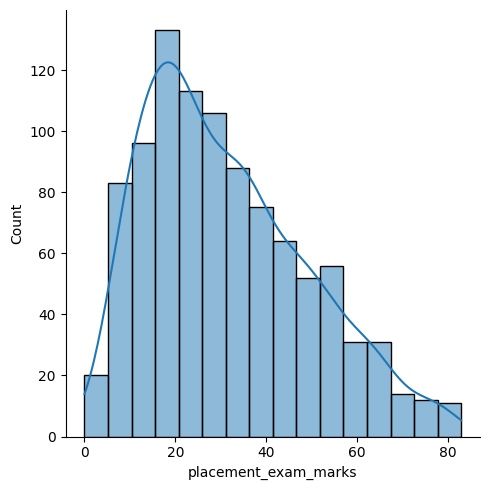

In [30]:
sns.displot(new_df['placement_exam_marks'], kde=True)

<Axes: xlabel='placement_exam_marks'>

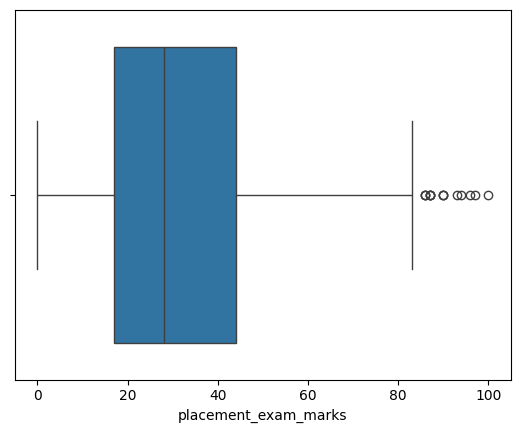

In [31]:
sns.boxplot(df['placement_exam_marks'], orient='h')

<Axes: xlabel='placement_exam_marks'>

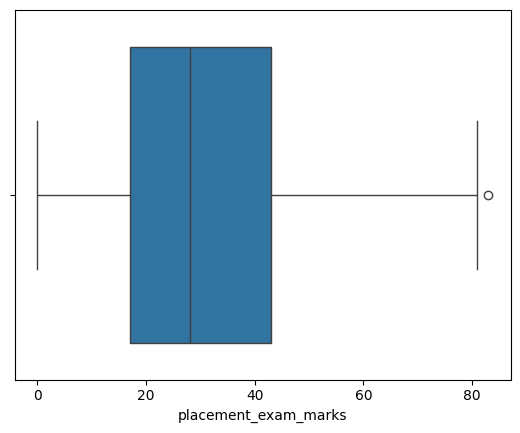

In [32]:
sns.boxplot(new_df['placement_exam_marks'], orient='h')

In [41]:
new_df_cap = df.copy()

In [42]:
new_df_cap

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0
...,...,...,...
995,8.87,44.0,1
996,9.12,65.0,1
997,4.89,34.0,0
998,8.62,46.0,1


In [43]:
new_df_cap['placement_exam_marks'] = np.where(new_df_cap['placement_exam_marks']>upper_limit,upper_limit,
                     np.where(new_df_cap['placement_exam_marks']<lower_limit,
                             lower_limit, new_df_cap['placement_exam_marks']))

In [44]:
new_df_cap

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0
...,...,...,...
995,8.87,44.0,1
996,9.12,65.0,1
997,4.89,34.0,0
998,8.62,46.0,1


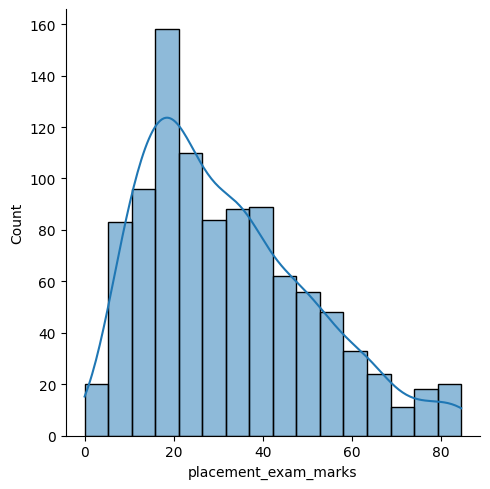

In [45]:
sns.displot(new_df_cap['placement_exam_marks'], kde=True)

<Axes: xlabel='placement_exam_marks'>

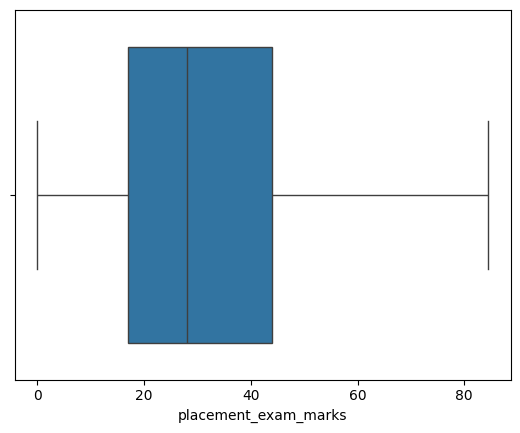

In [46]:
sns.boxplot(new_df_cap['placement_exam_marks'], orient='h')